# 📊 Exploratory Data Analysis (EDA)
### Heart Disease Prediction — MLOps Assignment

This notebook performs Exploratory Data Analysis (EDA) on the cleaned UCI Heart Disease dataset.  
The goals of this EDA are:

- Understand dataset structure  
- Explore distributions of numerical features  
- Analyze categorical variables  
- Check class balance  
- Identify correlations  
- Generate insights for feature engineering and model selection  

The dataset used here is the cleaned version generated by `src/data.py`.

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/heart_clean.csv")
df.head()

,age,gender,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## 📘 Dataset Overview

We begin by inspecting the dataset structure:

- Number of rows and columns  
- Data types  
- Summary statistics  
- First few records  

This helps verify that the cleaning step worked correctly and ensures no missing values remain.

In [4]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 297 entries, 0 to 296
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       297 non-null    float64
 1   gender    297 non-null    float64
 2   cp        297 non-null    float64
 3   trestbps  297 non-null    float64
 4   chol      297 non-null    float64
 5   fbs       297 non-null    float64
 6   restecg   297 non-null    float64
 7   thalach   297 non-null    float64
 8   exang     297 non-null    float64
 9   oldpeak   297 non-null    float64
 10  slope     297 non-null    float64
 11  ca        297 non-null    float64
 12  thal      297 non-null    float64
 13  num       297 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 32.6 KB


,age,gender,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
count,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000
mean,54.542088,0.676768,3.158249,131.693603,247.350168,0.144781,0.996633,149.599327,0.326599,1.055556,1.602694,0.676768,4.730640,0.461279
std,9.049736,0.468500,0.964859,17.762806,51.997583,0.352474,0.994914,22.941562,0.469761,1.166123,0.618187,0.938965,1.938629,0.499340
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,243.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,276.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,1.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,1.000000


## ❤️ Class Distribution (Target Variable)

The target variable `num` indicates heart disease:

- `0` → No heart disease  
- `1` → Heart disease present  

A balanced dataset is ideal, but medical datasets often show imbalance.  
We visualize the class distribution to understand the severity of imbalance.

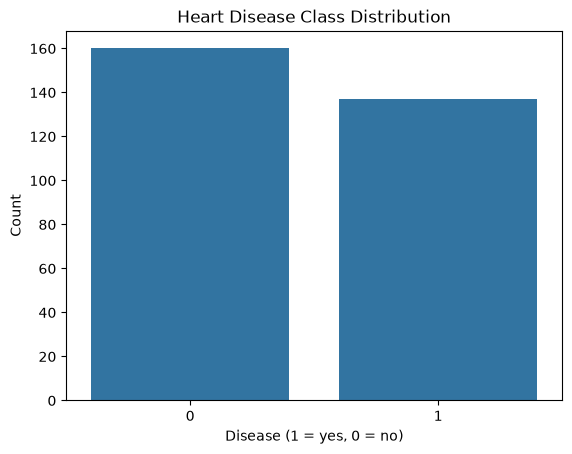

num
0    0.538721
1    0.461279
Name: proportion, dtype: float64

In [5]:
sns.countplot(x=df["num"])
plt.title("Heart Disease Class Distribution")
plt.xlabel("Disease (1 = yes, 0 = no)")
plt.ylabel("Count")
plt.show()

df["num"].value_counts(normalize=True)

## 📈 Numeric Feature Distributions

We plot histograms for key numerical features:

- `age`
- `trestbps` (resting blood pressure)
- `chol` (cholesterol)
- `thalach` (maximum heart rate)
- `oldpeak` (ST depression)

These plots help identify skewness, outliers, and general patterns.

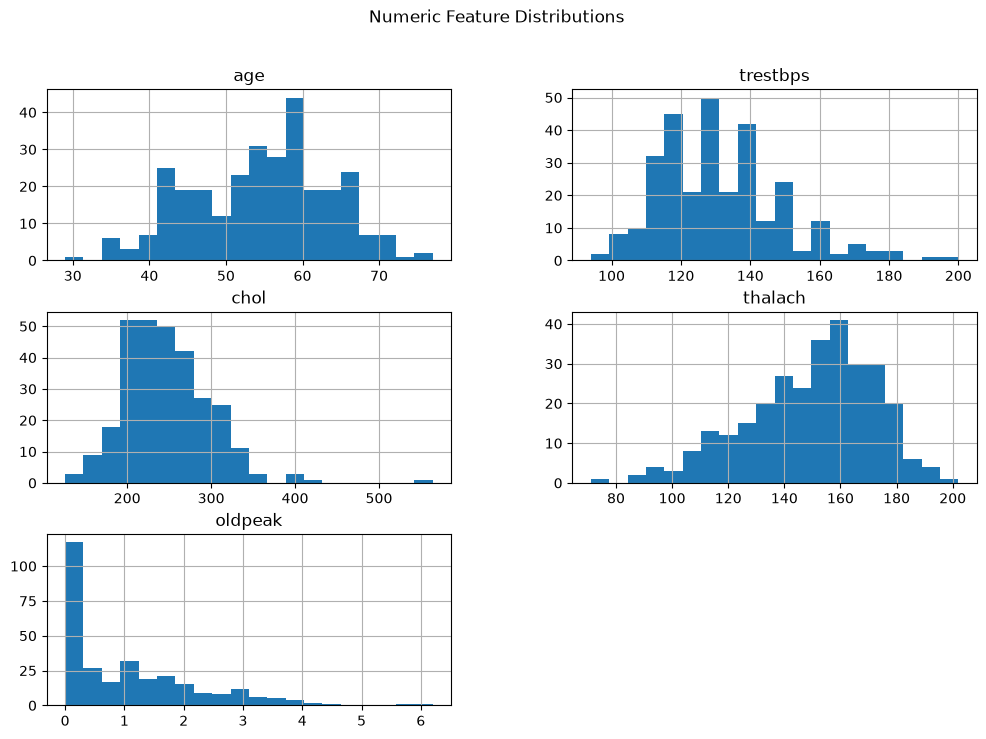

In [6]:
numeric_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]

df[numeric_cols].hist(figsize=(12, 8), bins=20)
plt.suptitle("Numeric Feature Distributions")
plt.show()

## 🔥 Correlation Heatmap

Correlation helps identify:

- Strongly related features  
- Redundant variables  
- Features that may influence the target  

This guides feature engineering and model selection.

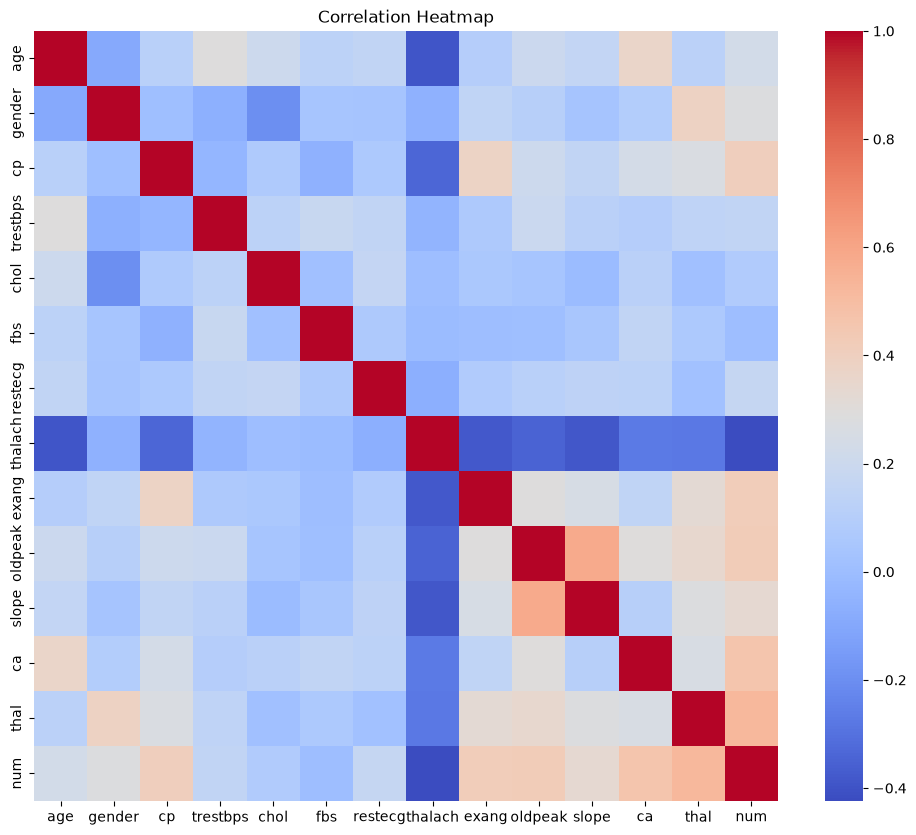

In [7]:
plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(), annot=False, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

## 👤 Gender Distribution

The dataset uses `gender` instead of `sex`:

- `0` → Female  
- `1` → Male  

We visualize gender distribution to understand demographic representation.

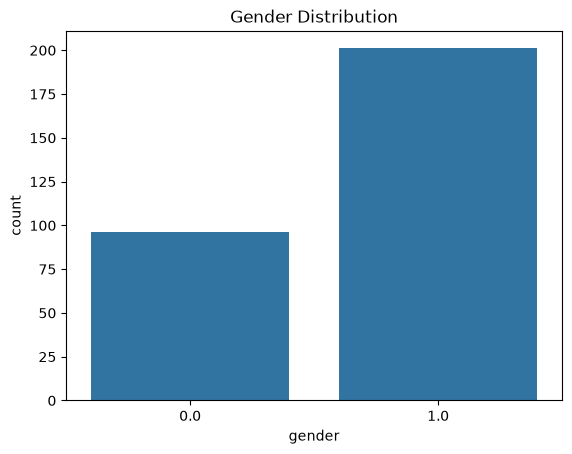

In [8]:
sns.countplot(x=df["gender"])
plt.title("Gender Distribution")
plt.show()

## 📊 Numeric Features vs Heart Disease

Boxplots show how numerical features differ between:

- Patients with heart disease  
- Patients without heart disease  
This helps identify predictive features.

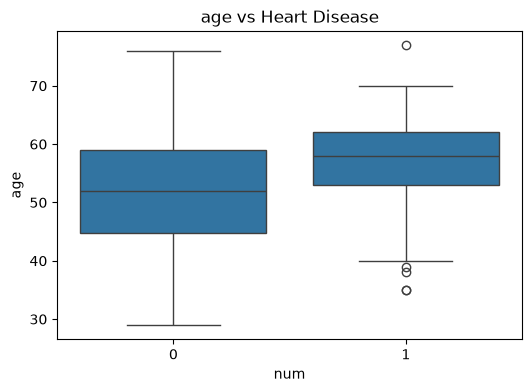

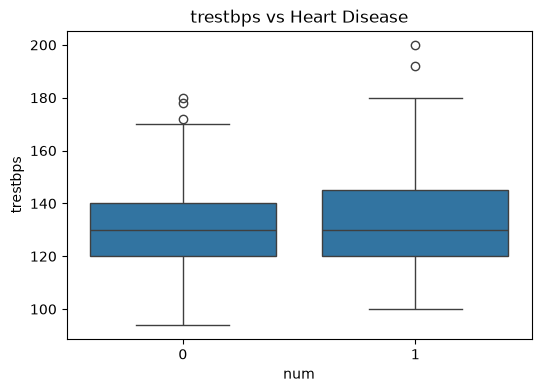

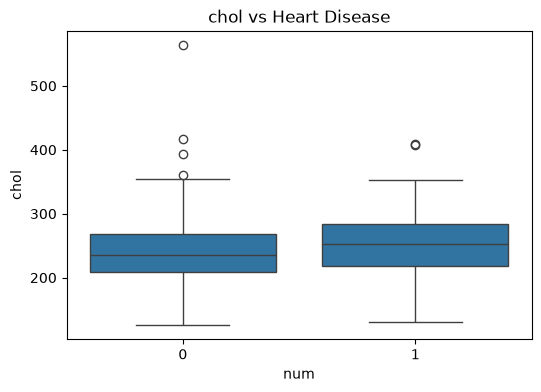

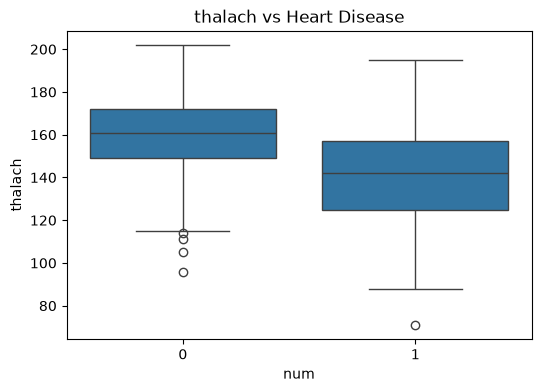

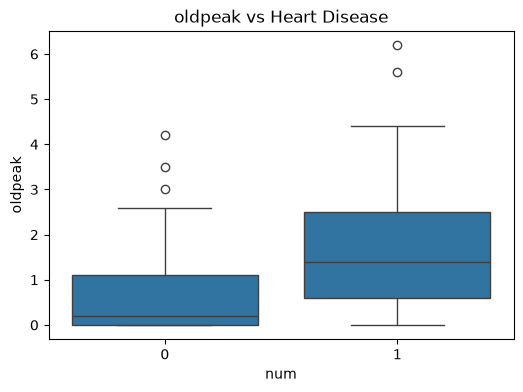

In [9]:
for col in numeric_cols:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x=df["num"], y=df[col])
    plt.title(f"{col} vs Heart Disease")
    plt.show()

## 🧩 Categorical Features vs Heart Disease

We analyze categorical variables:

- `gender`
- `cp` (chest pain type)
- `fbs` (fasting blood sugar)
- `restecg`
- `exang` (exercise-induced angina)
- `slope`
- `ca`
- `thal`

Countplots help visualize how categories relate to the presence of heart disease.

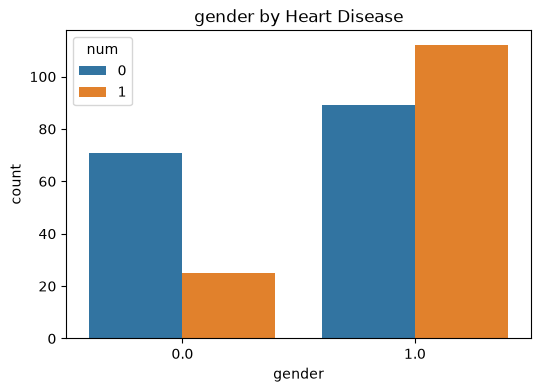

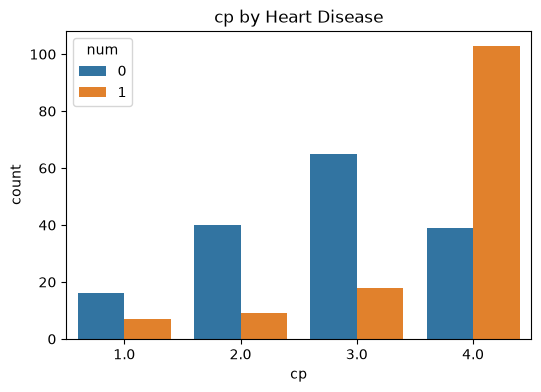

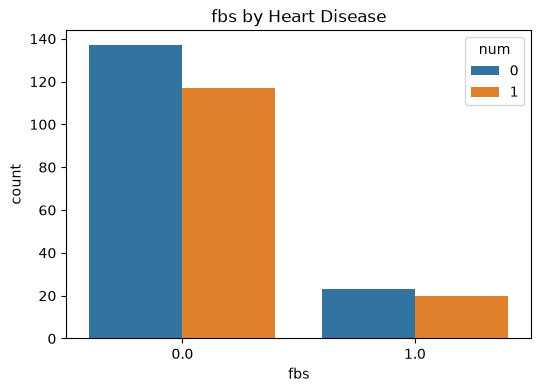

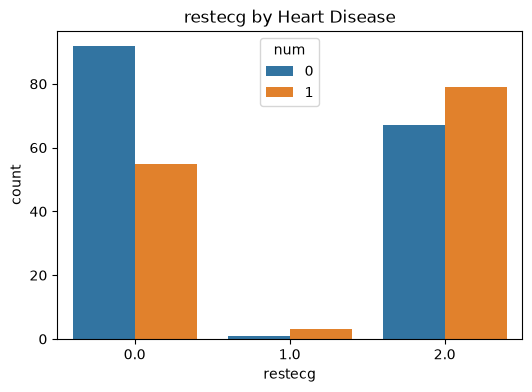

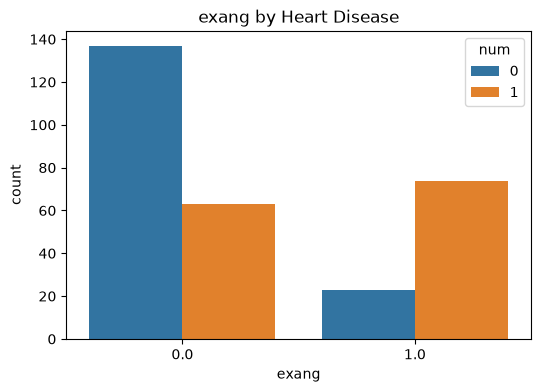

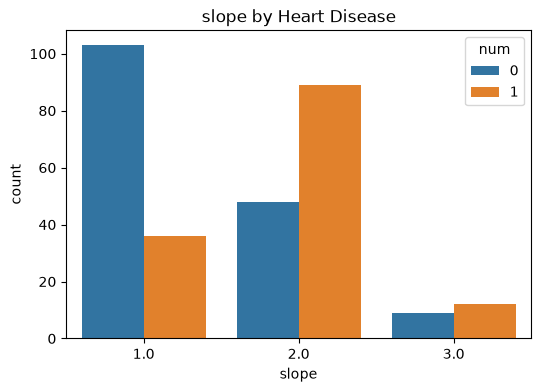

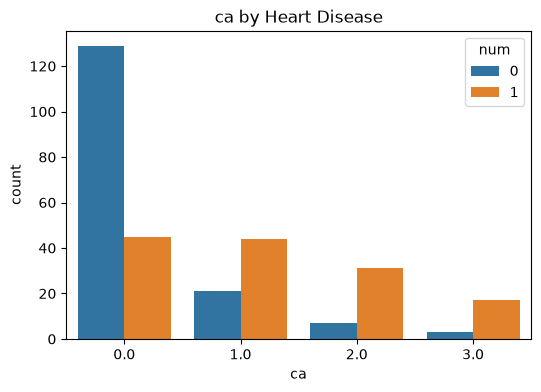

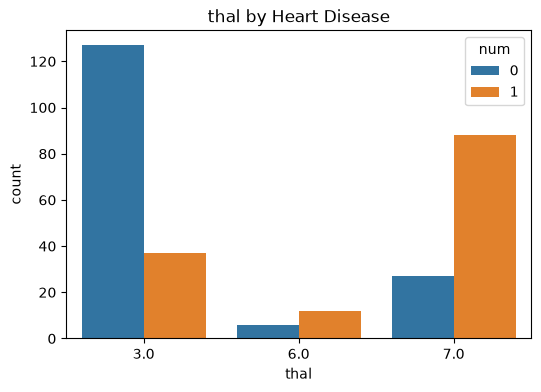

In [10]:
categorical_cols = ["gender", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

for col in categorical_cols:
    plt.figure(figsize=(6, 4))
    sns.countplot(x=df[col], hue=df["num"])
    plt.title(f"{col} by Heart Disease")
    plt.show()